# Gradient boosting hyperparameter tuning

This notebook tunes the histogram-based gradient boosting baseline using chronological validation. The search compares learning rate, maximum leaf nodes and L2 regularisation across three earlier validation windows. Average precision (PR-AUC) is the main selection metric, with ROC-AUC reported alongside it. Steps 30–35 are reserved for a subsequent check of the selected configuration.

Only transactions with known labels are used for supervised training and evaluation. The Kaggle test set is not used here.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)
from sklearn.model_selection import ParameterGrid

In [2]:
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "raw"

df = pd.read_csv(DATA_DIR / "train.csv")

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
print("Time range:", df["time_step"].min(), "-", df["time_step"].max())

Dataset shape: (141772, 168)
Columns: ['txId', 'time_step', 'feat_1', 'feat_2', 'feat_3', 'feat_4', 'feat_5', 'feat_6', 'feat_7', 'feat_8', 'feat_9', 'feat_10', 'feat_11', 'feat_12', 'feat_13', 'feat_14', 'feat_15', 'feat_16', 'feat_17', 'feat_18', 'feat_19', 'feat_20', 'feat_21', 'feat_22', 'feat_23', 'feat_24', 'feat_25', 'feat_26', 'feat_27', 'feat_28', 'feat_29', 'feat_30', 'feat_31', 'feat_32', 'feat_33', 'feat_34', 'feat_35', 'feat_36', 'feat_37', 'feat_38', 'feat_39', 'feat_40', 'feat_41', 'feat_42', 'feat_43', 'feat_44', 'feat_45', 'feat_46', 'feat_47', 'feat_48', 'feat_49', 'feat_50', 'feat_51', 'feat_52', 'feat_53', 'feat_54', 'feat_55', 'feat_56', 'feat_57', 'feat_58', 'feat_59', 'feat_60', 'feat_61', 'feat_62', 'feat_63', 'feat_64', 'feat_65', 'feat_66', 'feat_67', 'feat_68', 'feat_69', 'feat_70', 'feat_71', 'feat_72', 'feat_73', 'feat_74', 'feat_75', 'feat_76', 'feat_77', 'feat_78', 'feat_79', 'feat_80', 'feat_81', 'feat_82', 'feat_83', 'feat_84', 'feat_85', 'feat_86', 'fe

## Chronological validation

Models are fitted on earlier labelled transactions and evaluated on later time steps. The three tuning windows are 15–19, 20–24 and 25–29, with expanding training histories ending at steps 14, 19 and 24 respectively.

In [3]:
TARGET = "label"

feature_cols = [
    col for col in df.columns
    if col.startswith("feat_")
]

folds = [
    (14, 15, 19),
    (19, 20, 24),
    (24, 25, 29)
]

for train_end, val_start, val_end in folds:
    train_fold = df[df["time_step"] <= train_end]
    val_fold = df[
        df["time_step"].between(val_start, val_end)
    ]

    print(
        f"Train 1-{train_end}: {len(train_fold):,} rows | "
        f"Validation {val_start}-{val_end}: {len(val_fold):,} rows | "
        f"Illicit rate: {val_fold[TARGET].mean():.2%}"
    )

Train 1-14: 70,990 rows | Validation 15-19: 15,481 rows | Illicit rate: 16.36%
Train 1-19: 86,471 rows | Validation 20-24: 22,479 rows | Illicit rate: 12.60%
Train 1-24: 108,950 rows | Validation 25-29: 11,854 rows | Illicit rate: 23.50%


## Parameter search

The grid contains 12 combinations of learning rate (0.03, 0.05, 0.10), maximum leaf nodes (15, 31) and L2 regularisation (0, 1). Each configuration is evaluated on all three chronological windows, giving 36 fits in total.

In [4]:
param_grid = {
    "learning_rate": [0.03, 0.05, 0.10],
    "max_leaf_nodes": [15, 31],
    "l2_regularization": [0.0, 1.0]
}

configurations = list(ParameterGrid(param_grid))

print("Number of configurations:", len(configurations))
print("Total model fits:", len(configurations) * len(folds))

display(pd.DataFrame(configurations))

Number of configurations: 12
Total model fits: 36


,l2_regularization,learning_rate,max_leaf_nodes
0,0.0,0.03,15
1,0.0,0.03,31
2,0.0,0.05,15
3,0.0,0.05,31
4,0.0,0.10,15
5,0.0,0.10,31
6,1.0,0.03,15
7,1.0,0.03,31
8,1.0,0.05,15
9,1.0,0.05,31


In [6]:
print("Total transactions:", len(df))
print("Missing target labels:", df[TARGET].isna().sum())
print("Label distribution:")
print(df[TARGET].value_counts(dropna=False))

Total transactions: 141772
Missing target labels: 110537
Label distribution:
label
NaN    110537
0.0     27591
1.0      3644
Name: count, dtype: int64


In [8]:
# Keep transactions with known labels
labelled = df.dropna(subset=[TARGET]).copy()

# Convert labels to integers
labelled[TARGET] = labelled[TARGET].astype(int)

print("Original dataset:", df.shape)
print("Labelled dataset:", labelled.shape)
print("Missing labels:", labelled[TARGET].isna().sum())

Original dataset: (141772, 168)
Labelled dataset: (31235, 168)
Missing labels: 0


## Walk-forward results

The configurations are ranked by mean average precision across the three validation windows. The selected setting uses a learning rate of 0.10, 15 maximum leaf nodes and no L2 regularisation, with mean PR-AUC of 0.956860. Scores vary noticeably by period, so the mean should not be treated as a guarantee of future performance.

Refitting this configuration on labelled transactions through step 29 gives ROC-AUC 0.997831 and PR-AUC 0.990447 on steps 30–35.

In [10]:
results = []

for i, params in enumerate(configurations, start=1):

    for train_end, val_start, val_end in folds:

        train_fold = labelled[labelled["time_step"] <= train_end]

        val_fold = labelled[labelled["time_step"].between(val_start, val_end)]

        X_tr = train_fold[feature_cols]
        y_tr = train_fold[TARGET]

        X_va = val_fold[feature_cols]
        y_va = val_fold[TARGET]

        model = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", HistGradientBoostingClassifier(
                max_iter=200,
                learning_rate=params["learning_rate"],
                max_leaf_nodes=params["max_leaf_nodes"],
                l2_regularization=params["l2_regularization"],
                random_state=42
            ))
        ])

        model.fit(X_tr, y_tr)

        probs = model.predict_proba(X_va)[:, 1]

        results.append({
            **params,
            "validation": f"{val_start}-{val_end}",
            "roc_auc": roc_auc_score(y_va, probs),
            "pr_auc": average_precision_score(y_va, probs)
        })

    print(f"Completed configuration {i}/{len(configurations)}")

tuning_results = pd.DataFrame(results)

display(tuning_results.head())

Completed configuration 1/12
Completed configuration 2/12
Completed configuration 3/12
Completed configuration 4/12
Completed configuration 5/12
Completed configuration 6/12
Completed configuration 7/12
Completed configuration 8/12
Completed configuration 9/12
Completed configuration 10/12
Completed configuration 11/12
Completed configuration 12/12


,l2_regularization,learning_rate,max_leaf_nodes,validation,roc_auc,pr_auc
0,0.0,0.03,15,15-19,0.995750,0.988005
1,0.0,0.03,15,20-24,0.965671,0.887461
2,0.0,0.03,15,25-29,0.996324,0.988933
3,0.0,0.03,31,15-19,0.994263,0.986062
4,0.0,0.03,31,20-24,0.951660,0.877184


In [11]:
summary = (
    tuning_results
    .groupby(
        ["learning_rate", "max_leaf_nodes", "l2_regularization"]
    )
    .agg(
        mean_roc_auc=("roc_auc", "mean"),
        mean_pr_auc=("pr_auc", "mean"),
        std_pr_auc=("pr_auc", "std"),
        min_pr_auc=("pr_auc", "min")
    )
    .reset_index()
    .sort_values("mean_pr_auc", ascending=False)
)

display(summary)

best_params = summary.iloc[0][
    ["learning_rate", "max_leaf_nodes", "l2_regularization"]
].to_dict()

print("Best hyperparameters:", best_params)

,learning_rate,max_leaf_nodes,l2_regularization,mean_roc_auc,mean_pr_auc,std_pr_auc,min_pr_auc
8,0.10,15,0.0,0.984713,0.956860,0.060959,0.886506
4,0.05,15,0.0,0.985728,0.956236,0.060176,0.886831
0,0.03,15,0.0,0.985915,0.954800,0.058319,0.887461
5,0.05,15,1.0,0.984134,0.954031,0.060439,0.884261
7,0.05,31,1.0,0.981377,0.953110,0.062584,0.880880
9,0.10,15,1.0,0.982777,0.952991,0.063397,0.879798
3,0.03,31,1.0,0.982758,0.952658,0.060323,0.883009
1,0.03,15,1.0,0.983829,0.952118,0.061195,0.881458
6,0.05,31,0.0,0.981500,0.951972,0.063688,0.878476
2,0.03,31,0.0,0.980801,0.950761,0.063737,0.877184


Best hyperparameters: {'learning_rate': 0.1, 'max_leaf_nodes': 15.0, 'l2_regularization': 0.0}


In [12]:

from sklearn.base import clone
from sklearn.metrics import roc_auc_score, average_precision_score

# Final chronological validation
train_final = labelled[labelled["time_step"] <= 29]
val_final = labelled[labelled["time_step"].between(30, 35)]

X_train_final = train_final[feature_cols]
y_train_final = train_final[TARGET]

X_val_final = val_final[feature_cols]
y_val_final = val_final[TARGET]

# Refit using the selected hyperparameters
tuned_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", HistGradientBoostingClassifier(
        max_iter=200,
        learning_rate=0.10,
        max_leaf_nodes=15,
        l2_regularization=0.0,
        random_state=42
    ))
])

tuned_model.fit(X_train_final, y_train_final)

tuned_probs = tuned_model.predict_proba(X_val_final)[:, 1]

print("Tuned Gradient Boosting")
print("ROC-AUC:", roc_auc_score(y_val_final, tuned_probs))
print("PR-AUC:", average_precision_score(y_val_final, tuned_probs))


Tuned Gradient Boosting
ROC-AUC: 0.9978307957267658
PR-AUC: 0.990446875620369


## Classification threshold

PR-AUC evaluates the ranking of predicted fraud probabilities without fixing a classification threshold. For operational classification, the notebook also compares precision, recall and F1 at thresholds from 0.05 to 0.95 using predictions from earlier chronological folds.

The highest pooled F1 in this sweep occurs at threshold 0.30 (precision 0.9705, recall 0.8821, F1 0.9242). On the separate steps 30–35 holdout, the notebook reports confusion matrices at thresholds 0.50 and 0.30. Threshold choice does not change the probability scores used for Kaggle's ranking-based evaluation.

In [13]:
# Generate out-of-sample predictions on the tuning folds
from sklearn.base import clone
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use the previously defined folds and tuned_model
threshold_folds = [
    (14, 15, 19),
    (19, 20, 24),
    (24, 25, 29)
]

oof_predictions = []

for train_end, val_start, val_end in threshold_folds:

    train_fold = labelled[
        labelled["time_step"] <= train_end
    ]

    val_fold = labelled[
        labelled["time_step"].between(val_start, val_end)
    ]

    model = clone(tuned_model)

    model.fit(
        train_fold[feature_cols],
        train_fold[TARGET]
    )

    probs = model.predict_proba(
        val_fold[feature_cols]
    )[:, 1]

    fold_results = pd.DataFrame({
        "time_step": val_fold["time_step"].values,
        "actual": val_fold[TARGET].values,
        "probability": probs,
        "fold": f"{val_start}-{val_end}"
    })

    oof_predictions.append(fold_results)

oof_df = pd.concat(oof_predictions, ignore_index=True)

print("Out-of-sample predictions:", len(oof_df))
display(oof_df.head())


Out-of-sample predictions: 11485


,time_step,actual,probability,fold
0,15,0,0.000009,15-19
1,15,0,0.000007,15-19
2,15,0,0.000012,15-19
3,15,0,0.000006,15-19
4,15,0,0.000061,15-19


In [14]:
# Compare classification metrics across thresholds
thresholds = np.round(np.arange(0.05, 1.0, 0.05), 2)

results = []

for threshold in thresholds:

    predictions = (
        oof_df["probability"] >= threshold
    ).astype(int)

    results.append({
        "threshold": threshold,
        "precision": precision_score(
            oof_df["actual"], predictions,
            zero_division=0
        ),
        "recall": recall_score(
            oof_df["actual"], predictions,
            zero_division=0
        ),
        "f1": f1_score(
            oof_df["actual"], predictions,
            zero_division=0
        )
    })

threshold_results = pd.DataFrame(results)

display(threshold_results)


,threshold,precision,recall,f1
0,0.05,0.888017,0.909432,0.898597
1,0.10,0.936942,0.899786,0.917988
2,0.15,0.949886,0.893891,0.921038
3,0.20,0.957250,0.887996,0.921323
4,0.25,0.963827,0.885316,0.922905
5,0.30,0.970519,0.882101,0.924200
6,0.35,0.974420,0.877814,0.923597
7,0.40,0.978404,0.874062,0.923295
8,0.45,0.980641,0.868703,0.921284
9,0.50,0.982958,0.865488,0.920490


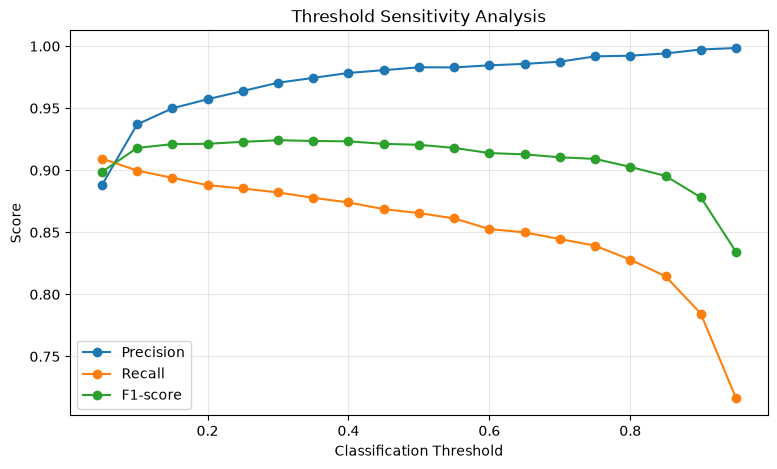

In [15]:
# Plot precision, recall and F1 across thresholds
plt.figure(figsize=(9, 5))

plt.plot(
    threshold_results["threshold"],
    threshold_results["precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_results["threshold"],
    threshold_results["recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_results["threshold"],
    threshold_results["f1"],
    marker="o",
    label="F1-score"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Threshold Sensitivity Analysis")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [16]:

best_row = threshold_results.loc[
    threshold_results["f1"].idxmax()
]

best_threshold = float(best_row["threshold"])

print("Best threshold:", best_threshold)
print("Precision:", best_row["precision"])
print("Recall:", best_row["recall"])
print("F1:", best_row["f1"])


Best threshold: 0.3
Precision: 0.9705188679245284
Recall: 0.8821007502679529
F1: 0.9241998877035373


In [17]:

from sklearn.metrics import classification_report

for threshold in [0.5, best_threshold]:

    predictions = (
        tuned_probs >= threshold
    ).astype(int)

    print(f"\nThreshold: {threshold:.2f}")

    print(classification_report(
        y_val_final,
        predictions,
        zero_division=0
    ))

    print("Confusion matrix:")
    print(confusion_matrix(
        y_val_final,
        predictions
    ))



Threshold: 0.50
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      4081
           1       0.98      0.95      0.97       773

    accuracy                           0.99      4854
   macro avg       0.99      0.97      0.98      4854
weighted avg       0.99      0.99      0.99      4854

Confusion matrix:
[[4068   13]
 [  40  733]]

Threshold: 0.30
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      4081
           1       0.96      0.97      0.96       773

    accuracy                           0.99      4854
   macro avg       0.98      0.98      0.98      4854
weighted avg       0.99      0.99      0.99      4854

Confusion matrix:
[[4047   34]
 [  26  747]]
